# Pod Service Reuse — Baseline vs Sequential vs Concurrent


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})

# Pre-computed values
data = {
    'Baseline U2':    {'energy_kj': 214.99, 'duration_min': 85.78,  'throughput': 12.78},
    'Baseline U4':    {'energy_kj': 432.18, 'duration_min': 172.89, 'throughput': 12.68},
    'Sequential U2':  {'energy_kj': 182.41, 'duration_min': 57.78,  'throughput': 18.97},
    'Sequential U4':  {'energy_kj': 365.87, 'duration_min': 115.60, 'throughput': 18.96},
    'Concurrent U2':  {'energy_kj': 180.53, 'duration_min': 54.02,  'throughput': 20.29},
    'Concurrent U4':  {'energy_kj': 358.78, 'duration_min': 105.85, 'throughput': 20.71},
}

scenarios = ['Baseline', 'Sequential\nPod Service', 'Concurrent\nPod Service']
keys_u2 = ['Baseline U2', 'Sequential U2', 'Concurrent U2']
keys_u4 = ['Baseline U4', 'Sequential U4', 'Concurrent U4']

x = np.arange(len(scenarios))
width = 0.35
colors_u2 = ['#1f77b4', '#6baed6', '#c6dbef']
colors_u4 = ['#d62728', '#ef6548', '#fca082']

def add_labels(ax, bars, fmt='{:.1f}', suffix=''):
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2., h*1.01,
                    fmt.format(h) + suffix, ha='center', va='bottom', fontsize=9)

print('Setup done')

Setup done


## Plot 1 — Total Energy Consumption

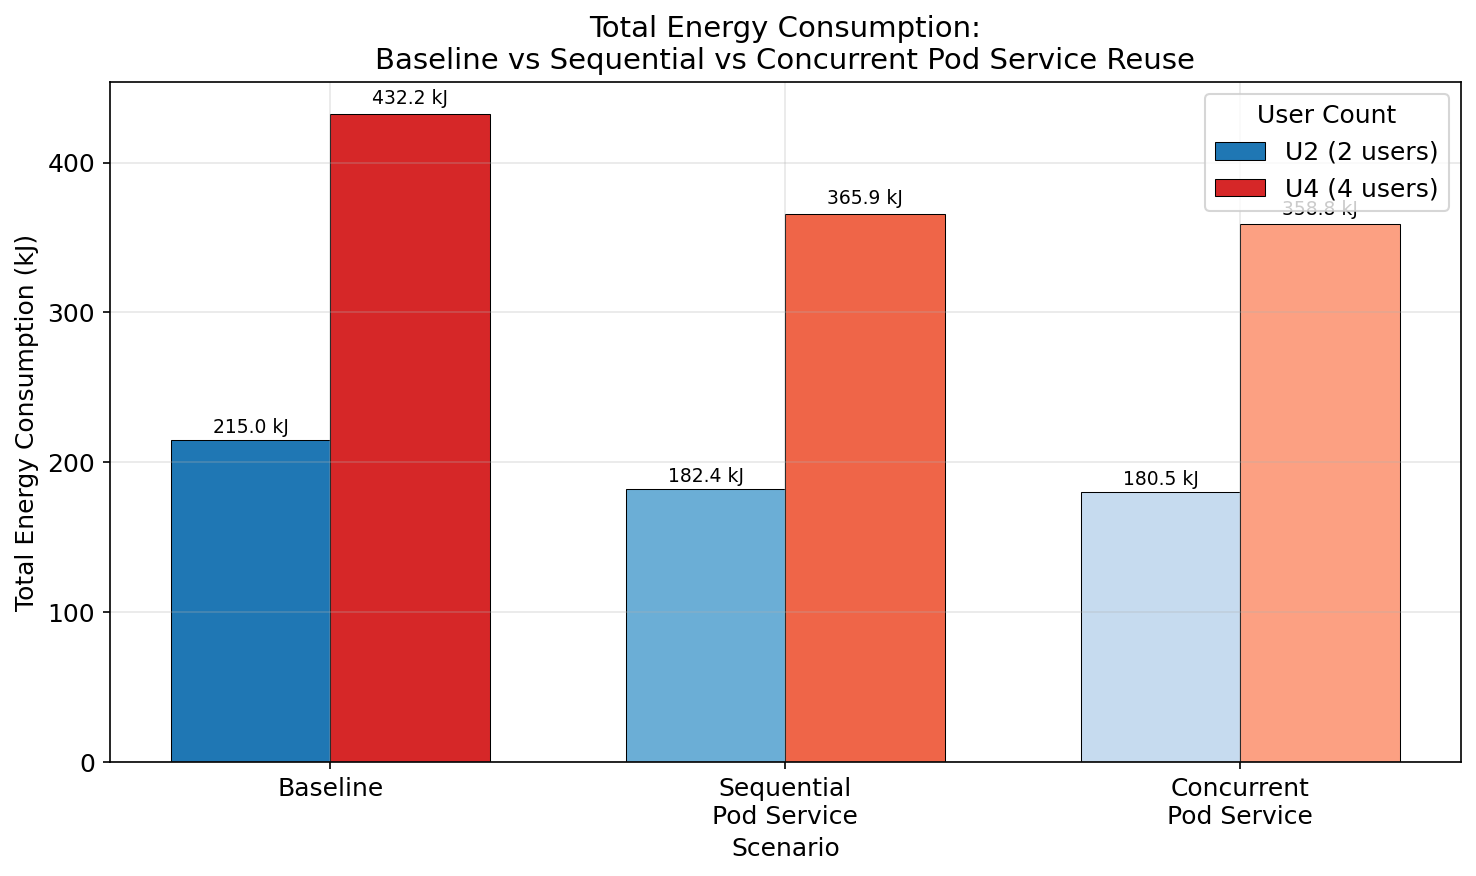

Saved: pod_compare_energy.pdf


In [2]:
fig, ax = plt.subplots(figsize=(10, 6))

energy_u2 = [data[k]['energy_kj'] for k in keys_u2]
energy_u4 = [data[k]['energy_kj'] for k in keys_u4]

bars1 = ax.bar(x - width/2, energy_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, energy_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)
add_labels(ax, bars1, '{:.1f}', ' kJ')
add_labels(ax, bars2, '{:.1f}', ' kJ')

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Energy Consumption (kJ)')
ax.set_title('Total Energy Consumption:\nBaseline vs Sequential vs Concurrent Pod Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('pod_compare_energy.pdf', bbox_inches='tight')
plt.savefig('pod_compare_energy.png', bbox_inches='tight')
plt.show()
print('Saved: pod_compare_energy.pdf')

## Plot 2 — Pipeline Duration

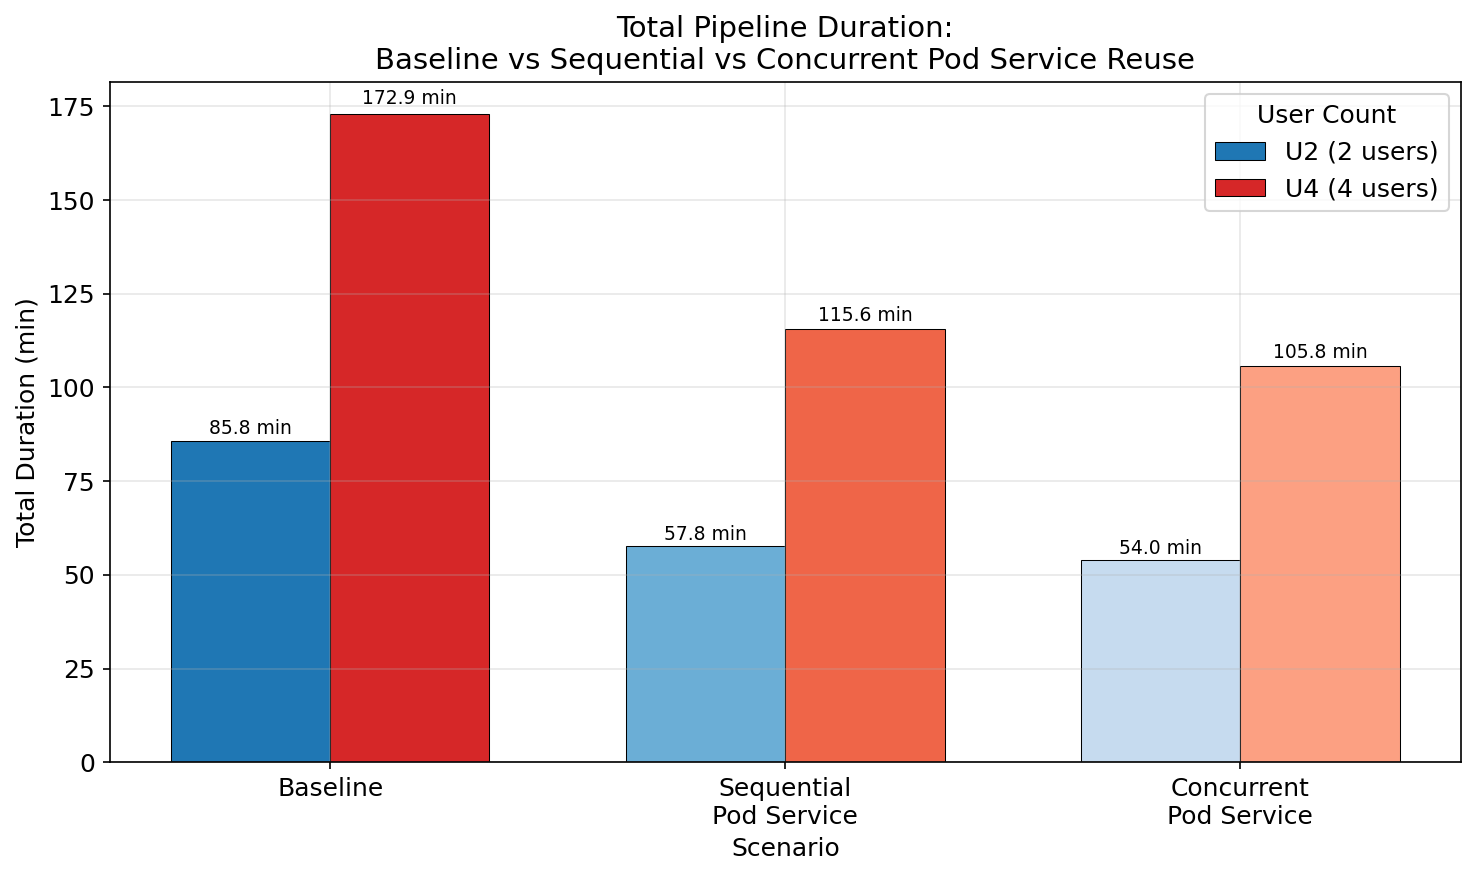

Saved: pod_compare_duration.pdf


In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

dur_u2 = [data[k]['duration_min'] for k in keys_u2]
dur_u4 = [data[k]['duration_min'] for k in keys_u4]

bars1 = ax.bar(x - width/2, dur_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, dur_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)
add_labels(ax, bars1, '{:.1f}', ' min')
add_labels(ax, bars2, '{:.1f}', ' min')

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Duration (min)')
ax.set_title('Total Pipeline Duration:\nBaseline vs Sequential vs Concurrent Pod Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('pod_compare_duration.pdf', bbox_inches='tight')
plt.savefig('pod_compare_duration.png', bbox_inches='tight')
plt.show()
print('Saved: pod_compare_duration.pdf')

## Plot 3 — System Throughput

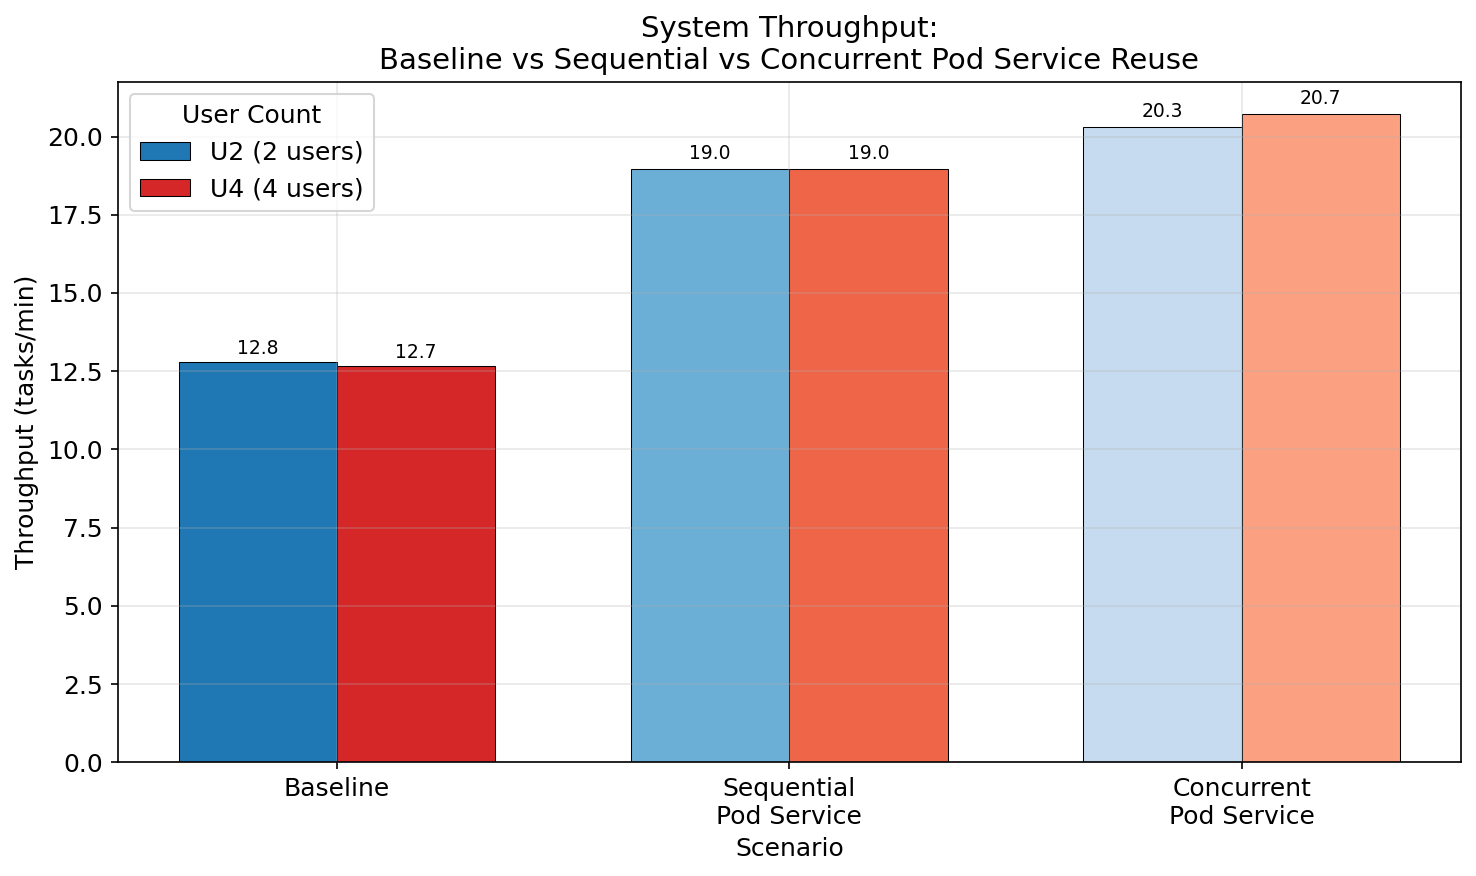

Saved: pod_compare_throughput.pdf


In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

tp_u2 = [data[k]['throughput'] for k in keys_u2]
tp_u4 = [data[k]['throughput'] for k in keys_u4]

bars1 = ax.bar(x - width/2, tp_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, tp_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)
add_labels(ax, bars1, '{:.1f}', '')
add_labels(ax, bars2, '{:.1f}', '')

ax.set_xlabel('Scenario')
ax.set_ylabel('Throughput (tasks/min)')
ax.set_title('System Throughput:\nBaseline vs Sequential vs Concurrent Pod Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('pod_compare_throughput.pdf', bbox_inches='tight')
plt.savefig('pod_compare_throughput.png', bbox_inches='tight')
plt.show()
print('Saved: pod_compare_throughput.pdf')

## Plot 4 — Combined Savings vs Baseline (%)

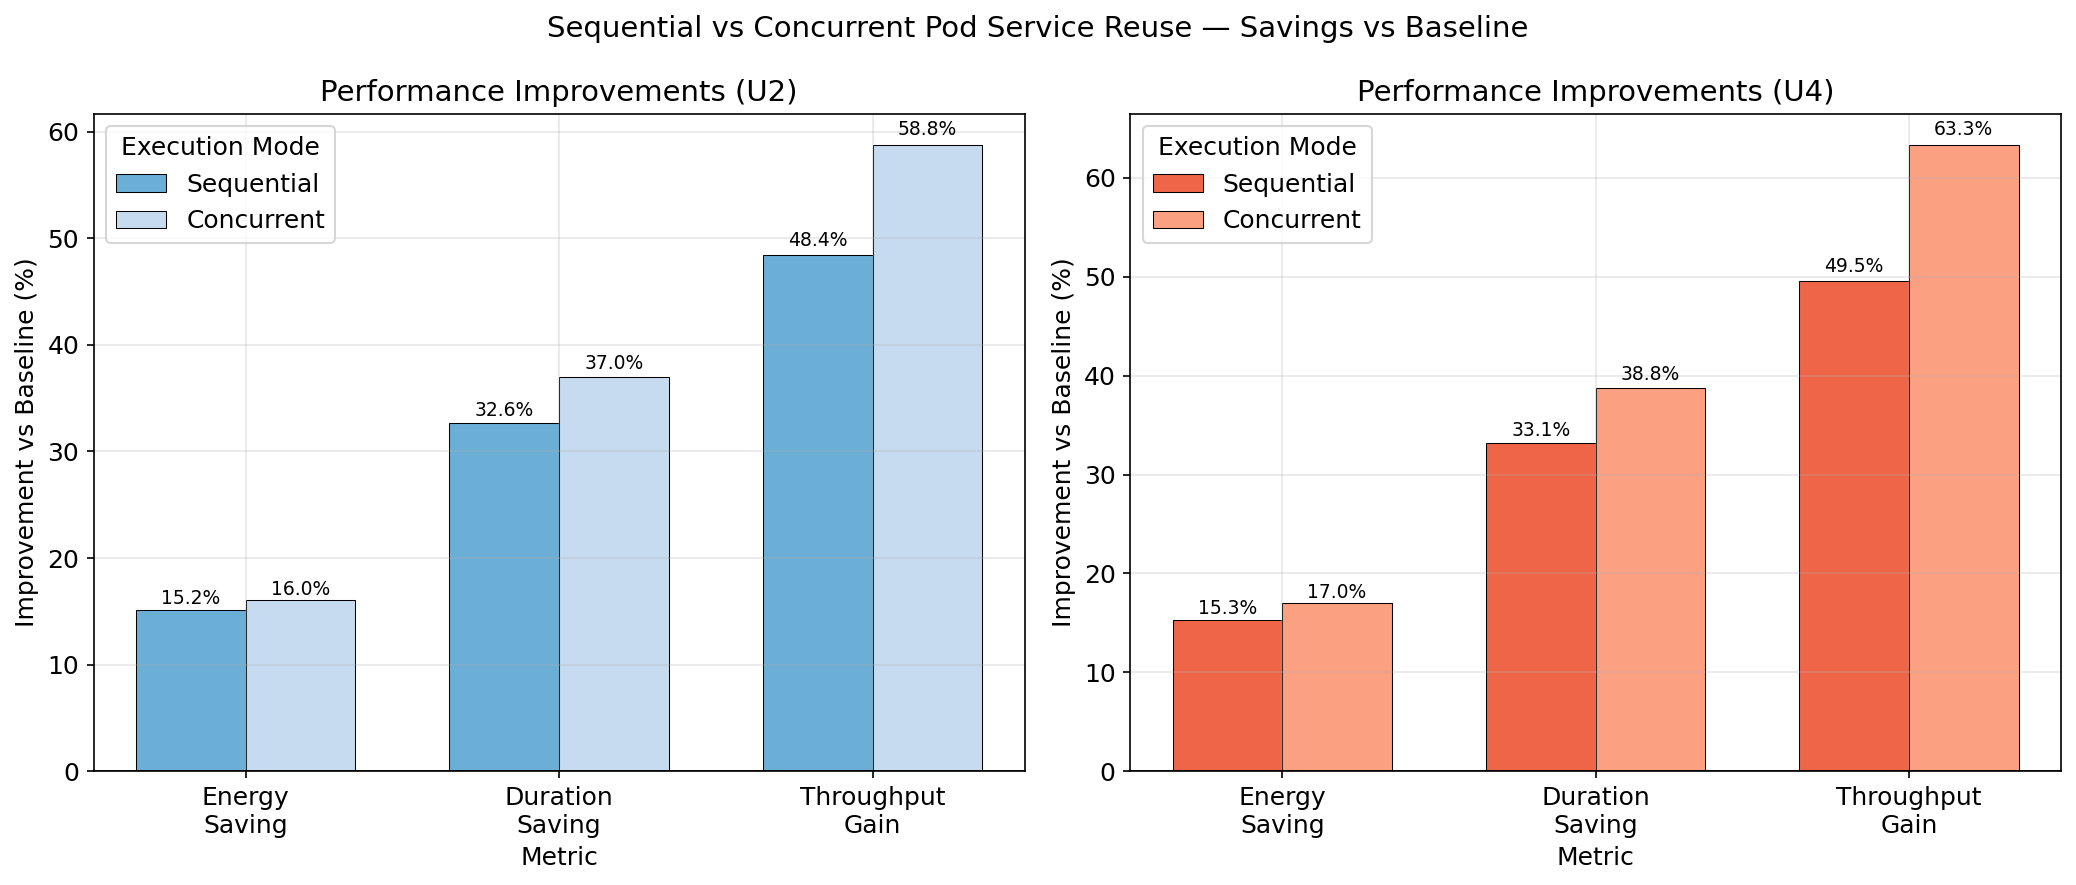

Saved: pod_compare_savings.pdf


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

metrics = ['Energy\nSaving', 'Duration\nSaving', 'Throughput\nGain']
xm = np.arange(len(metrics))
w = 0.35

for ax, u_label, base_key, seq_key, conc_key, cu2, cu4 in [
    (axes[0], 'U2', 'Baseline U2', 'Sequential U2', 'Concurrent U2',
     ['#6baed6', '#c6dbef'], ['#6baed6', '#c6dbef']),
    (axes[1], 'U4', 'Baseline U4', 'Sequential U4', 'Concurrent U4',
     ['#ef6548', '#fca082'], ['#ef6548', '#fca082'])
]:
    base_e = data[base_key]['energy_kj']
    base_d = data[base_key]['duration_min']
    base_t = data[base_key]['throughput']

    seq_savings = [
        (base_e - data[seq_key]['energy_kj']) / base_e * 100,
        (base_d - data[seq_key]['duration_min']) / base_d * 100,
        (data[seq_key]['throughput'] - base_t) / base_t * 100,
    ]
    conc_savings = [
        (base_e - data[conc_key]['energy_kj']) / base_e * 100,
        (base_d - data[conc_key]['duration_min']) / base_d * 100,
        (data[conc_key]['throughput'] - base_t) / base_t * 100,
    ]

    bars1 = ax.bar(xm - w/2, seq_savings, w, label='Sequential', color='#6baed6' if 'U2' in u_label else '#ef6548', edgecolor='black', linewidth=0.5)
    bars2 = ax.bar(xm + w/2, conc_savings, w, label='Concurrent', color='#c6dbef' if 'U2' in u_label else '#fca082', edgecolor='black', linewidth=0.5)

    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

    ax.set_xlabel('Metric')
    ax.set_ylabel('Improvement vs Baseline (%)')
    ax.set_title(f'Performance Improvements ({u_label})')
    ax.set_xticks(xm)
    ax.set_xticklabels(metrics)
    ax.legend(title='Execution Mode')
    ax.axhline(y=0, color='black', linewidth=0.8)

plt.suptitle('Sequential vs Concurrent Pod Service Reuse — Savings vs Baseline', fontsize=14)
plt.tight_layout()
plt.savefig('pod_compare_savings.pdf', bbox_inches='tight')
plt.savefig('pod_compare_savings.png', bbox_inches='tight')
plt.show()
print('Saved: pod_compare_savings.pdf')

## Summary Table

In [6]:
import pandas as pd
rows = []
for name, d in data.items():
    u = 2 if 'U2' in name else 4
    base_key = f'Baseline {"U2" if u==2 else "U4"}'
    base_e = data[base_key]['energy_kj']
    base_d = data[base_key]['duration_min']
    base_t = data[base_key]['throughput']
    rows.append({
        'Experiment': name,
        'Energy (kJ)': d['energy_kj'],
        'Duration (min)': d['duration_min'],
        'Throughput (t/min)': d['throughput'],
        'Energy Saving (%)': round((base_e - d['energy_kj']) / base_e * 100, 1),
        'Duration Saving (%)': round((base_d - d['duration_min']) / base_d * 100, 1),
        'Throughput Gain (%)': round((d['throughput'] - base_t) / base_t * 100, 1),
    })
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv('pod_service_comparison_summary.csv', index=False)
print('\nSaved: pod_service_comparison_summary.csv')

   Experiment  Energy (kJ)  Duration (min)  Throughput (t/min)  Energy Saving (%)  Duration Saving (%)  Throughput Gain (%)
  Baseline U2       214.99           85.78               12.78                0.0                  0.0                  0.0
  Baseline U4       432.18          172.89               12.68                0.0                  0.0                  0.0
Sequential U2       182.41           57.78               18.97               15.2                 32.6                 48.4
Sequential U4       365.87          115.60               18.96               15.3                 33.1                 49.5
Concurrent U2       180.53           54.02               20.29               16.0                 37.0                 58.8
Concurrent U4       358.78          105.85               20.71               17.0                 38.8                 63.3

Saved: pod_service_comparison_summary.csv
